In [1]:
import os, math, time, random, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
import matplotlib.pyplot as plt
import pandas as pd

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
OUT = "outputs_part3"
os.makedirs(OUT, exist_ok=True)
print(f"torch {torch.__version__} | torchvision {torchvision.__version__} | device: {DEVICE} | mixed precision: {USE_AMP}")
if DEVICE.type == "cpu":
    print("No GPU found. In Colab: Runtime > Change runtime type > GPU. Full training on CPU will take many hours.")

torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | device: cuda | mixed precision: True


## 1. Configuration

In [2]:
FAST_DEV_RUN = False   # True = 1 epoch on the 10% split and a 1,000-image test subset, to check the pipeline

CFG = dict(
    data_fracs=(0.1, 1.0),
    epochs={0.1: 100, 1.0: 30},      # the small split needs more passes over its data to converge
    batch=128, lr=0.1, momentum=0.9, wd=5e-4, warmup_epochs=2, label_smoothing=0.1,
    widths=(64, 128, 256), blocks=(2, 2, 2),
    n_clusters=4, kmeans_iters=3, n_heads=4,
    occlusion=12, seed=0, num_workers=2,
)
EVAL_SUBSET = None                   # None = full 10,000-image test set

if FAST_DEV_RUN:
    CFG.update(data_fracs=(0.1,), epochs={0.1: 1})
    EVAL_SUBSET = 1000
CFG

{'data_fracs': (0.1, 1.0),
 'epochs': {0.1: 100, 1.0: 30},
 'batch': 128,
 'lr': 0.1,
 'momentum': 0.9,
 'wd': 0.0005,
 'warmup_epochs': 2,
 'label_smoothing': 0.1,
 'widths': (64, 128, 256),
 'blocks': (2, 2, 2),
 'n_clusters': 4,
 'kmeans_iters': 3,
 'n_heads': 4,
 'occlusion': 12,
 'seed': 0,
 'num_workers': 2}

## 2. Data
Standard CIFAR augmentation from the course (random crop with padding, horizontal flip) and per-channel normalization. After normalization a value of 0 equals the dataset mean, which is what the occlusion test fills in.

100%|██████████| 169M/169M [44:19<00:00, 63.5kB/s]


 10% split:  5000 training images (50 per class)
100% split: 50000 training images (500 per class)


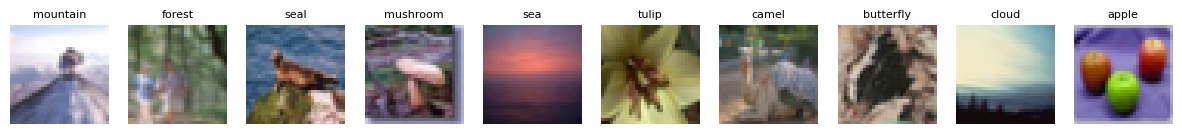

In [3]:
MEAN, STD = (0.5071, 0.4865, 0.4409), (0.2673, 0.2564, 0.2762)
train_tf = transforms.Compose([transforms.RandomCrop(32, padding=4), transforms.RandomHorizontalFlip(),
                               transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
test_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

train_full = torchvision.datasets.CIFAR100("data", train=True, download=True, transform=train_tf)
test_set = torchvision.datasets.CIFAR100("data", train=False, download=True, transform=test_tf)
CLASSES = train_full.classes
if EVAL_SUBSET is not None:
    test_set = Subset(test_set, list(range(EVAL_SUBSET)))

def stratified_subset(targets, frac, seed):
    rng = np.random.default_rng(seed)
    targets = np.asarray(targets)
    idx = []
    for c in range(len(CLASSES)):
        ci = np.where(targets == c)[0]
        n = max(1, int(round(frac * len(ci))))
        idx.extend(rng.choice(ci, n, replace=False).tolist())
    return sorted(idx)

SPLITS = {f: stratified_subset(train_full.targets, f, CFG["seed"]) for f in CFG["data_fracs"]}
for f, idx in SPLITS.items():
    print(f"{int(f * 100):3d}% split: {len(idx):5d} training images ({len(idx) // len(CLASSES)} per class)")

PIN = DEVICE.type == "cuda"
test_loader = DataLoader(test_set, batch_size=256, shuffle=False, num_workers=CFG["num_workers"], pin_memory=PIN)

def unnormalize(x):
    return (x * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)).clamp(0, 1)

fig, axes = plt.subplots(1, 10, figsize=(15, 1.9))
raw_test = torchvision.datasets.CIFAR100("data", train=False, download=False, transform=test_tf)
for i, ax in enumerate(axes):
    x, y = raw_test[i]
    ax.imshow(unnormalize(x).permute(1, 2, 0))
    ax.set_title(CLASSES[y], fontsize=8)
    ax.axis("off")
plt.show()

## 3. Model

### 3.1 Backbone
A CIFAR-style ResNet built from scratch (He et al., 2016; EECS 498 Lecture 8): a 3x3 stem and three stages of two basic blocks, with 64, 128 and 256 channels. Only stages two and three downsample, so the final feature map is 8x8. That gives 64 spatial positions, enough for the cluster and attention maps to be readable.

In [4]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.shortcut = nn.Identity()
        if stride != 1 or cin != cout:
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))


class ResNetBackbone(nn.Module):
    def __init__(self, widths=(64, 128, 256), blocks=(2, 2, 2)):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU())
        layers, cin = [], widths[0]
        for i, (w, n) in enumerate(zip(widths, blocks)):
            for b in range(n):
                layers.append(BasicBlock(cin, w, stride=2 if (i > 0 and b == 0) else 1))
                cin = w
        self.layers = nn.Sequential(*layers)
        self.out_ch = widths[-1]

    def forward(self, x):
        return self.layers(self.stem(x))     # [B, C, 8, 8] for 32x32 input

### 3.2 Pooling heads
Every head maps the feature map `[B, C, 8, 8]` to logits. The attention heads keep the plain mean as a residual, so they can fall back to GAP when that works best.

The clustered head:
1. adds a learned position embedding and LayerNorm to the 64 position tokens;
2. picks 4 starting centroids by farthest-point selection, then runs 3 steps of differentiable soft k-means with a temperature scaled to the spread of the tokens;
3. lets one learned query attend over the 4 centroids and the 64 positions (a type embedding marks which is which).

The clustering runs in float32 even under mixed precision, and uses squared distances directly because a Euclidean distance has no gradient at zero.

In [5]:
def farthest_point_init(H, M):
    # H: [N, k, d] -> M starting centroids per item, [N, M, d]
    idx = torch.arange(H.shape[0], device=H.device)
    d_ref = ((H - H.mean(1, keepdim=True)) ** 2).sum(-1)
    cents, d_sel = [], None
    for _ in range(M):
        score = d_ref if d_sel is None else d_sel
        c = H[idx, score.argmax(1)]
        cents.append(c)
        dc = ((H - c[:, None]) ** 2).sum(-1)
        d_sel = dc if d_sel is None else torch.minimum(d_sel, dc)
    return torch.stack(cents, dim=1)

def soft_kmeans(H, init, iters, tau, eps=1e-3):
    # returns centroids [N, M, d] and soft assignments [N, k, M]
    mu, a = init, None
    for _ in range(iters):
        d2 = ((H[:, :, None] - mu[:, None]) ** 2).sum(-1)
        a = torch.softmax(-d2 / tau, dim=-1)
        mass = a.sum(1)
        mu = (a.transpose(1, 2) @ H + eps * mu) / (mass[..., None] + eps)
    return mu, a


class GAPHead(nn.Module):
    def __init__(self, C, n_cls, hw):
        super().__init__()
        self.fc = nn.Linear(C, n_cls)
        self.last_attn, self.last_assign = None, None

    def forward(self, f):
        return self.fc(f.mean((2, 3)))


class AttnPoolHead(nn.Module):
    def __init__(self, C, n_cls, hw, n_heads, use_clusters=False, n_clusters=4, iters=3):
        super().__init__()
        self.use_clusters, self.M, self.iters, self.hw = use_clusters, n_clusters, iters, hw
        self.pos = nn.Parameter(torch.randn(1, hw, C) * 0.02)
        self.norm = nn.LayerNorm(C)
        self.query = nn.Parameter(torch.randn(1, 1, C) * 0.02)
        self.attn = nn.MultiheadAttention(C, n_heads, batch_first=True)
        if use_clusters:
            self.log_tau = nn.Parameter(torch.zeros(()))
            self.type_emb = nn.Parameter(torch.zeros(2, C))     # 0 = centroid token, 1 = position token
        self.fc = nn.Linear(C, n_cls)
        self.last_attn, self.last_assign = None, None

    def forward(self, f):
        B = f.shape[0]
        t = f.flatten(2).transpose(1, 2)                         # [B, HW, C]
        mean = t.mean(1)
        t = self.norm(t + self.pos)
        if self.use_clusters:
            with torch.autocast(device_type=t.device.type, enabled=False):
                tf = t.float()
                spread = ((tf - tf.mean(1, keepdim=True)) ** 2).sum(-1).mean().detach().clamp_min(1e-6)
                mu, assign = soft_kmeans(tf, farthest_point_init(tf, self.M), self.iters, self.log_tau.exp() * spread)
            self.last_assign = assign.detach()
            t = torch.cat([mu.to(t.dtype) + self.type_emb[0], t + self.type_emb[1]], dim=1)
        out, w = self.attn(self.query.expand(B, -1, -1), t, t, need_weights=True)
        self.last_attn = w.detach()                              # [B, 1, n_tokens]
        return self.fc(out[:, 0] + mean.to(out.dtype))


VARIANTS = {"GAP (baseline)": "gap", "Attention pooling": "attn", "Clustered attention pooling": "cluster"}

class Net(nn.Module):
    def __init__(self, variant, cfg, n_cls=100):
        super().__init__()
        self.backbone = ResNetBackbone(cfg["widths"], cfg["blocks"])
        C, hw = self.backbone.out_ch, 64
        if variant == "gap":
            self.head = GAPHead(C, n_cls, hw)
        elif variant == "attn":
            self.head = AttnPoolHead(C, n_cls, hw, cfg["n_heads"], use_clusters=False)
        elif variant == "cluster":
            self.head = AttnPoolHead(C, n_cls, hw, cfg["n_heads"], use_clusters=True,
                                     n_clusters=cfg["n_clusters"], iters=cfg["kmeans_iters"])
        else:
            raise ValueError(variant)

    def forward(self, x):
        return self.head(self.backbone(x))

### 3.3 Unit tests

In [6]:
torch.manual_seed(0)
x = torch.randn(4, 3, 32, 32, device=DEVICE)
for name, v in VARIANTS.items():
    m = Net(v, CFG).to(DEVICE)
    f = m.backbone(x)
    assert f.shape == (4, CFG["widths"][-1], 8, 8), f.shape
    out = m(x)
    assert out.shape == (4, 100) and torch.isfinite(out).all(), name
    F.cross_entropy(out, torch.zeros(4, dtype=torch.long, device=DEVICE)).backward()
    assert all(torch.isfinite(p.grad).all() for p in m.parameters() if p.grad is not None), name
    n_back = sum(p.numel() for p in m.backbone.parameters())
    n_head = sum(p.numel() for p in m.head.parameters())
    print(f"{name:28s} backbone {n_back / 1e6:.2f}M | head {n_head / 1e3:.1f}K params")
    if v == "cluster":
        a = m.head.last_assign
        assert a.shape == (4, 64, CFG["n_clusters"]) and torch.allclose(a.sum(-1), torch.ones_like(a.sum(-1)), atol=1e-4)
        assert m.head.last_attn.shape == (4, 1, CFG["n_clusters"] + 64)
    if v == "gap":
        assert torch.allclose(m.head(f), m.head.fc(f.mean((2, 3))))

# soft k-means must separate two clearly different groups of positions
Hs = torch.cat([torch.zeros(1, 32, 8), torch.full((1, 32, 8), 5.0)], dim=1) + 0.01 * torch.randn(1, 64, 8)
_, a = soft_kmeans(Hs, farthest_point_init(Hs, 2), 3, tau=1.0)
labels = a[0].argmax(-1)
assert (labels[:32] == labels[0]).all() and (labels[32:] == labels[32]).all() and labels[0] != labels[32]
print("all unit tests passed")

GAP (baseline)               backbone 2.78M | head 25.7K params
Attention pooling            backbone 2.78M | head 306.0K params
Clustered attention pooling  backbone 2.78M | head 306.5K params
all unit tests passed


## 4. Training
Every run uses the recipe from the course's training lectures: SGD with Nesterov momentum, linear warm-up then cosine decay, weight decay on weights only (not on norms, biases, embeddings or queries), label smoothing, and mixed precision on GPU.

In [7]:
def make_optimizer(model, cfg):
    no_decay_keys = ("pos", "query", "type_emb", "log_tau")
    decay, no_decay = [], []
    for n, p in model.named_parameters():
        (decay if p.ndim >= 2 and not any(k in n for k in no_decay_keys) else no_decay).append(p)
    return torch.optim.SGD([{"params": decay, "weight_decay": cfg["wd"]}, {"params": no_decay, "weight_decay": 0.0}],
                           lr=cfg["lr"], momentum=cfg["momentum"], nesterov=True)


def occlude(x, size, gen):
    # fill one random size x size square per image with 0 (the dataset mean after normalization)
    B, _, H, W = x.shape
    i = torch.randint(0, H - size + 1, (B,), generator=gen)
    j = torch.randint(0, W - size + 1, (B,), generator=gen)
    r, c = torch.arange(H), torch.arange(W)
    mr = (r[None] >= i[:, None]) & (r[None] < i[:, None] + size)
    mc = (c[None] >= j[:, None]) & (c[None] < j[:, None] + size)
    return x.masked_fill((mr[:, :, None] & mc[:, None, :])[:, None], 0.0)


def expected_calibration_error(probs, y, n_bins=15):
    conf, pred = probs.max(1)
    acc = (pred == y).float()
    edges = torch.linspace(0, 1, n_bins + 1)
    ece = torch.zeros(())
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.float().mean() * (acc[m].mean() - conf[m].mean()).abs()
    return ece.item()


@torch.no_grad()
def evaluate(model, loader, occlusion=0, seed=0):
    model.eval()
    g = torch.Generator().manual_seed(seed)
    logits, ys = [], []
    for x, y in loader:
        if occlusion:
            x = occlude(x, occlusion, g)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            out = model(x.to(DEVICE, non_blocking=True))
        logits.append(out.float().cpu())
        ys.append(y)
    logits, y = torch.cat(logits), torch.cat(ys)
    probs = logits.softmax(1)
    return dict(top1=(logits.argmax(1) == y).float().mean().item() * 100,
                top5=(logits.topk(5, 1).indices == y[:, None]).any(1).float().mean().item() * 100,
                nll=F.cross_entropy(logits, y).item(),
                ece=expected_calibration_error(probs, y) * 100)


def train_run(variant, frac, cfg):
    set_seed(cfg["seed"])
    model = Net(variant, cfg).to(DEVICE)
    loader = DataLoader(Subset(train_full, SPLITS[frac]), batch_size=cfg["batch"], shuffle=True, drop_last=True,
                        num_workers=cfg["num_workers"], pin_memory=PIN)
    epochs = cfg["epochs"][frac]
    total, warm = epochs * len(loader), max(1, cfg["warmup_epochs"] * len(loader))
    opt = make_optimizer(model, cfg)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    hist, t0 = [], time.time()
    eval_every = max(1, epochs // 10)
    for ep in range(1, epochs + 1):
        model.train()
        tot, correct, n = 0.0, 0, 0
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                out = model(x)
                loss = F.cross_entropy(out, y, label_smoothing=cfg["label_smoothing"])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            tot += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
        row = dict(epoch=ep, train_loss=tot / n, train_acc=correct / n * 100)
        if ep % eval_every == 0 or ep == epochs:
            row["test_top1"] = evaluate(model, test_loader)["top1"]
            print(f"  epoch {ep:3d}/{epochs} | loss {row['train_loss']:.3f} | train {row['train_acc']:5.1f}% | "
                  f"test {row['test_top1']:5.1f}% | {time.time() - t0:5.0f}s")
        hist.append(row)
    return model, pd.DataFrame(hist), (time.time() - t0) / 60


results, curves, models = [], {}, {}
for frac in CFG["data_fracs"]:
    for name, v in VARIANTS.items():
        print(f"\n=== {name} | {int(frac * 100)}% of training data ===")
        model, hist, minutes = train_run(v, frac, CFG)
        clean = evaluate(model, test_loader)
        occ = evaluate(model, test_loader, occlusion=CFG["occlusion"], seed=1)
        results.append(dict(model=name, data=f"{int(frac * 100)}%", **clean, occluded_top1=occ["top1"],
                            head_params_k=sum(p.numel() for p in model.head.parameters()) / 1e3, train_min=minutes))
        curves[(name, frac)] = hist
        models[(name, frac)] = model
        torch.save(model.state_dict(), f"{OUT}/{v}_{int(frac * 100)}pct.pt")
        print(f"  final: top1 {clean['top1']:.2f} | top5 {clean['top5']:.2f} | ECE {clean['ece']:.2f} | occluded top1 {occ['top1']:.2f}")


=== GAP (baseline) | 10% of training data ===
  epoch  10/100 | loss 3.329 | train  24.6% | test  18.1% |    23s
  epoch  20/100 | loss 2.500 | train  47.0% | test  26.2% |    45s
  epoch  30/100 | loss 1.695 | train  74.8% | test  28.6% |    67s
  epoch  40/100 | loss 1.111 | train  97.9% | test  34.3% |    89s
  epoch  50/100 | loss 0.948 | train 100.0% | test  36.0% |   111s
  epoch  60/100 | loss 0.894 | train 100.0% | test  37.6% |   134s
  epoch  70/100 | loss 0.869 | train 100.0% | test  38.9% |   157s
  epoch  80/100 | loss 0.856 | train 100.0% | test  39.0% |   180s
  epoch  90/100 | loss 0.850 | train 100.0% | test  39.2% |   202s
  epoch 100/100 | loss 0.849 | train 100.0% | test  39.2% |   225s
  final: top1 39.16 | top5 64.07 | ECE 3.45 | occluded top1 29.25

=== Attention pooling | 10% of training data ===
  epoch  10/100 | loss 3.288 | train  25.7% | test  18.3% |    24s
  epoch  20/100 | loss 2.447 | train  48.7% | test  22.9% |    48s
  epoch  30/100 | loss 1.633 | tr

## 5. Results

In [13]:
df = pd.DataFrame(results)
df["occlusion_drop"] = df["top1"] - df["occluded_top1"]
df.to_csv(f"{OUT}/results.csv", index=False)
cols = ["model", "data", "top1", "top5", "nll", "ece", "occluded_top1", "occlusion_drop", "head_params_k", "train_min"]
display(df[cols].round(2))

base = df[df.model == "GAP (baseline)"].set_index("data")
print("Change relative to GAP on the same data split (accuracy points; lower ECE and drop are better):")
for _, r in df[df.model != "GAP (baseline)"].iterrows():
    b = base.loc[r.data]
    print(f"  {r.model:28s} {r.data:>4s}: top1 {r.top1 - b.top1:+.2f} | occluded {r.occluded_top1 - b.occluded_top1:+.2f} | ECE {r.ece - b.ece:+.2f}")

,model,data,top1,top5,nll,ece,occluded_top1,occlusion_drop,head_params_k,train_min
0,GAP (baseline),10%,39.16,64.07,2.71,3.45,29.25,9.91,25.70,3.74
1,Attention pooling,10%,40.47,65.47,2.66,7.67,29.50,10.97,306.02,3.99
2,Clustered attention pooling,10%,40.13,65.48,2.66,7.10,29.62,10.51,306.53,4.68
3,GAP (baseline),100%,74.45,92.79,1.01,5.88,53.94,20.51,25.70,10.18
4,Attention pooling,100%,74.11,92.55,1.02,6.01,53.91,20.20,306.02,10.59
5,Clustered attention pooling,100%,73.87,92.18,1.03,5.75,54.08,19.79,306.53,12.39


Change relative to GAP on the same data split (accuracy points; lower ECE and drop are better):
  Attention pooling             10%: top1 +1.31 | occluded +0.25 | ECE +4.22
  Clustered attention pooling   10%: top1 +0.97 | occluded +0.37 | ECE +3.65
  Attention pooling            100%: top1 -0.34 | occluded -0.03 | ECE +0.14
  Clustered attention pooling  100%: top1 -0.58 | occluded +0.14 | ECE -0.12


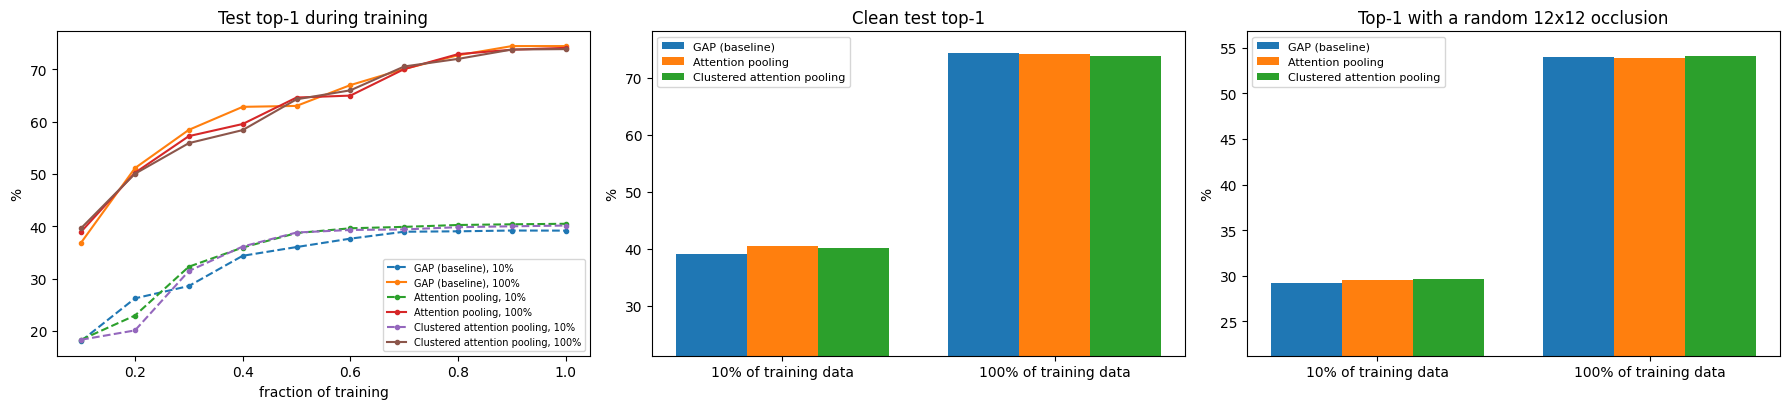

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for name in VARIANTS:
    for frac, ls in zip(CFG["data_fracs"], ["--", "-"]):
        h = curves[(name, frac)].dropna(subset=["test_top1"])
        axes[0].plot(h["epoch"] / h["epoch"].max(), h["test_top1"], ls, marker="o", ms=3, label=f"{name}, {int(frac * 100)}%")
axes[0].set_title("Test top-1 during training"); axes[0].set_xlabel("fraction of training"); axes[0].set_ylabel("%")
axes[0].legend(fontsize=7)

datas = list(dict.fromkeys(df["data"]))
x = np.arange(len(datas))
w = 0.26
for i, name in enumerate(VARIANTS):
    sub = df[df.model == name].set_index("data").reindex(datas)
    axes[1].bar(x + (i - 1) * w, sub["top1"], w, label=name)
    axes[2].bar(x + (i - 1) * w, sub["occluded_top1"], w, label=name)
for ax, t in zip(axes[1:], ["Clean test top-1", f"Top-1 with a random {CFG['occlusion']}x{CFG['occlusion']} occlusion"]):
    ax.set_xticks(x); ax.set_xticklabels([f"{d} of training data" for d in datas])
    ax.set_ylabel("%"); ax.set_title(t); ax.legend(fontsize=8)
    lo = df[["top1", "occluded_top1"]].values.min()
    ax.set_ylim(max(0, lo - 8), None)
plt.tight_layout()
plt.savefig(f"{OUT}/results.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Visualizing and understanding
Grad-CAM (Selvaraju et al., 2017; EECS 498 Lecture 14) weights each channel of the final feature map by the gradient of the true-class score and sums them. Because every variant shares the same backbone shape, the maps are directly comparable. Next to it: where the attention query looks, and how the clustered head splits the image into 4 regions without any part labels.

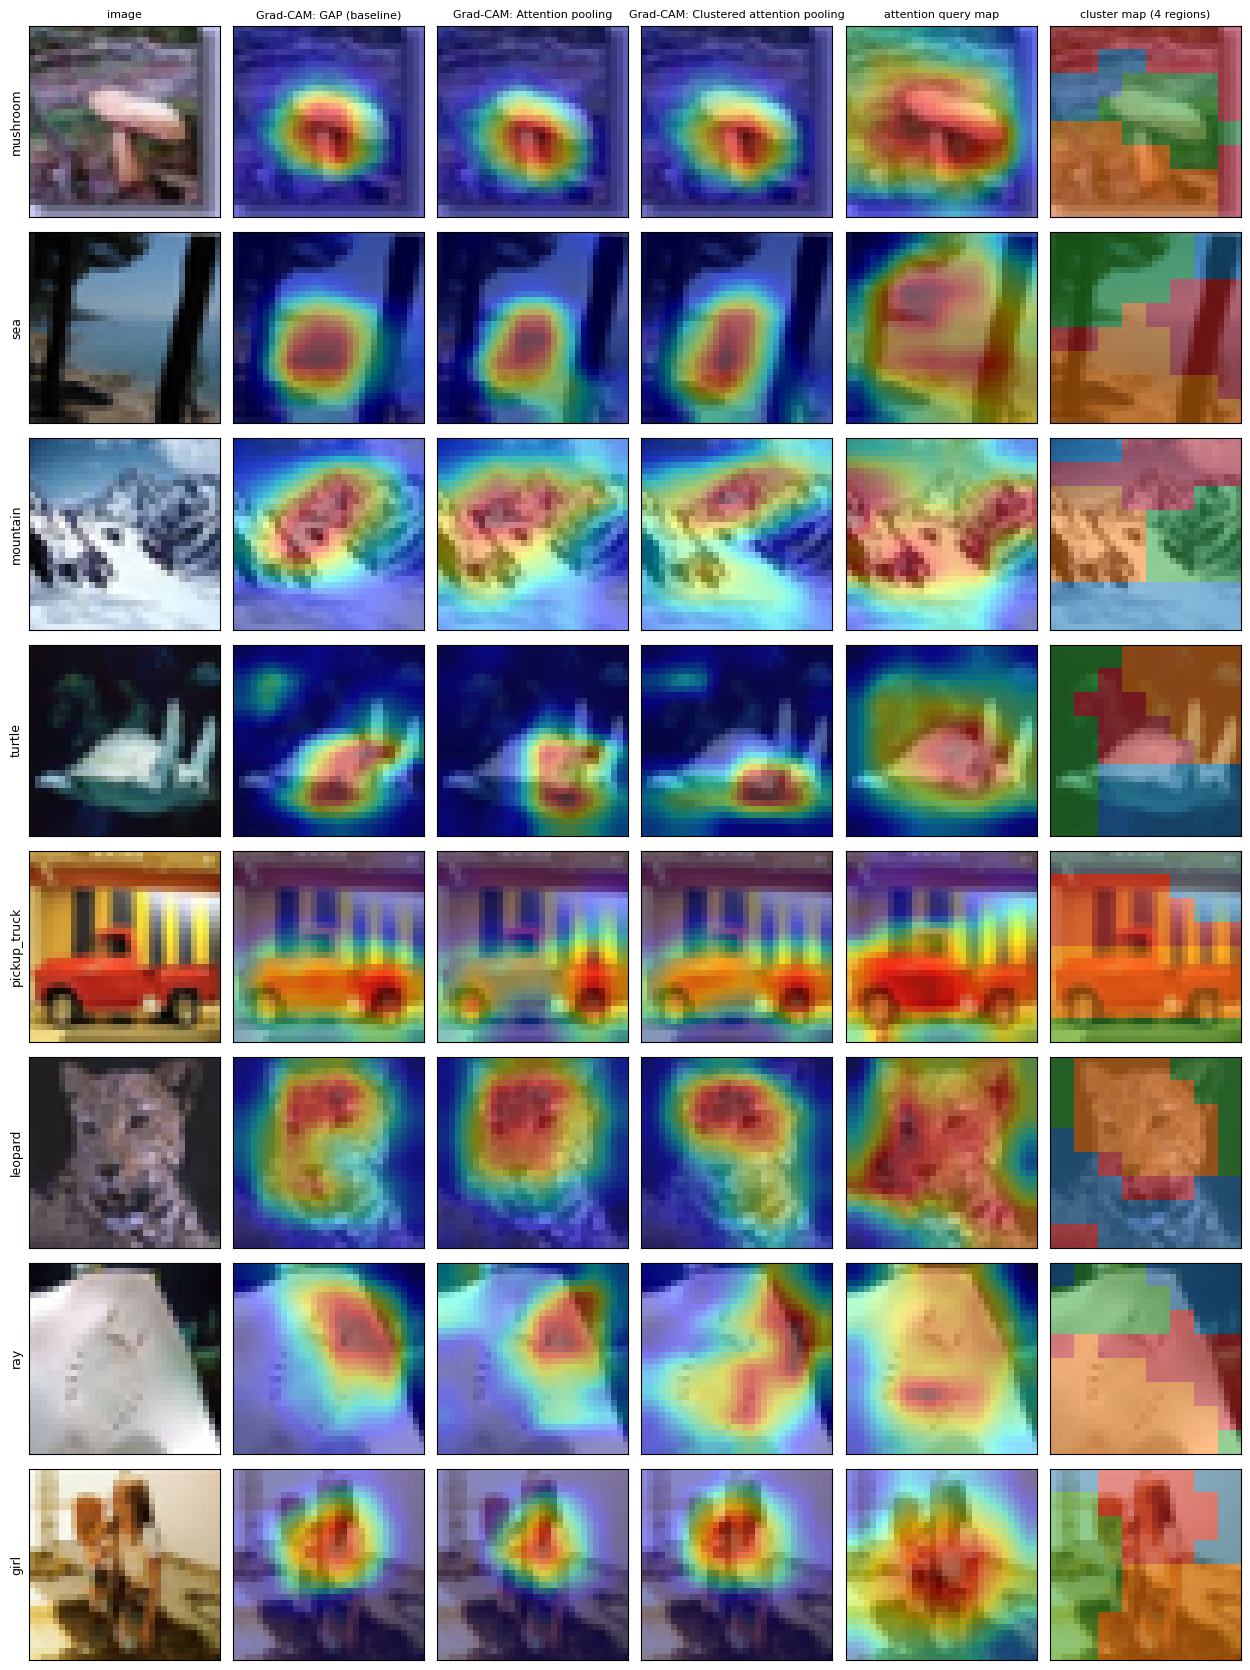

In [15]:
def grad_cam(model, x, cls):
    model.eval()
    with torch.enable_grad():
        f = model.backbone(x)
        score = model.head(f).gather(1, cls[:, None]).sum()
        g, = torch.autograd.grad(score, f)
    cam = F.relu((g.mean((2, 3), keepdim=True) * f).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    cam = cam / cam.flatten(1).max(1).values.clamp_min(1e-8)[:, None, None]
    return cam.detach().cpu()

frac_vis = max(CFG["data_fracs"])
show_idx = [3, 10, 21, 33, 47, 58, 72, 99]
xs = torch.stack([raw_test[i][0] for i in show_idx]).to(DEVICE)
ys = torch.tensor([raw_test[i][1] for i in show_idx], device=DEVICE)
imgs = torch.stack([unnormalize(x) for x in xs.cpu()]).permute(0, 2, 3, 1).numpy()

cams = {name: grad_cam(models[(name, frac_vis)], xs, ys) for name in VARIANTS}
with torch.no_grad():
    m_att = models[("Attention pooling", frac_vis)].eval(); m_att(xs)
    att_map = m_att.head.last_attn[:, 0].reshape(-1, 1, 8, 8).float()
    m_cl = models[("Clustered attention pooling", frac_vis)].eval(); m_cl(xs)
    parts = m_cl.head.last_assign.argmax(-1).reshape(-1, 1, 8, 8).float()
att_map = F.interpolate(att_map, size=32, mode="bilinear", align_corners=False)[:, 0].cpu()
parts = F.interpolate(parts, size=32, mode="nearest")[:, 0].cpu()

cols = ["image"] + [f"Grad-CAM: {n}" for n in VARIANTS] + ["attention query map", "cluster map (4 regions)"]
fig, axes = plt.subplots(len(show_idx), len(cols), figsize=(2.1 * len(cols), 2.1 * len(show_idx)))
for r in range(len(show_idx)):
    axes[r, 0].imshow(imgs[r]); axes[r, 0].set_ylabel(CLASSES[ys[r].item()], fontsize=9)
    for c, name in enumerate(VARIANTS, start=1):
        axes[r, c].imshow(imgs[r]); axes[r, c].imshow(cams[name][r], cmap="jet", alpha=0.45)
    axes[r, 4].imshow(imgs[r]); axes[r, 4].imshow(att_map[r], cmap="jet", alpha=0.45)
    axes[r, 5].imshow(imgs[r]); axes[r, 5].imshow(parts[r], cmap="tab10", vmin=0, vmax=9, alpha=0.5)
    for c in range(len(cols)):
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(cols[c], fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT}/grad_cam_and_parts.png", dpi=150, bbox_inches="tight")
plt.show()

In [16]:
# How concentrated is each model's evidence? Fraction of Grad-CAM mass in the top 20% of pixels, over 512 test images.
sub_idx = list(range(512))
xb = torch.stack([raw_test[i][0] for i in sub_idx]).to(DEVICE)
yb = torch.tensor([raw_test[i][1] for i in sub_idx], device=DEVICE)
rows = []
for name in VARIANTS:
    cam = torch.cat([grad_cam(models[(name, frac_vis)], xb[i:i + 128], yb[i:i + 128]) for i in range(0, len(sub_idx), 128)])
    flat = cam.flatten(1)
    k = int(0.2 * flat.shape[1])
    conc = flat.topk(k, 1).values.sum(1) / flat.sum(1).clamp_min(1e-8)
    rows.append(dict(model=name, cam_mass_in_top20pct=conc.mean().item()))
display(pd.DataFrame(rows).round(3))
print("1.0 = all evidence in a fifth of the image; 0.2 = evidence spread evenly. More concentrated is not automatically better.")

,model,cam_mass_in_top20pct
0,GAP (baseline),0.482
1,Attention pooling,0.483
2,Clustered attention pooling,0.482


1.0 = all evidence in a fifth of the image; 0.2 = evidence spread evenly. More concentrated is not automatically better.


In [12]:
# Plain-language summary generated from the numbers above
for d in datas:
    b = df[(df.model == "GAP (baseline)") & (df.data == d)].iloc[0]
    c = df[(df.model == "Clustered attention pooling") & (df.data == d)].iloc[0]
    a = df[(df.model == "Attention pooling") & (df.data == d)].iloc[0]
    print(f"{d:>4s} data | top1 GAP {b.top1:.2f}, attention {a.top1:.2f}, clustered {c.top1:.2f} | "
          f"occluded GAP {b.occluded_top1:.2f}, attention {a.occluded_top1:.2f}, clustered {c.occluded_top1:.2f}")
print("\nThis is one seed. Differences under about 0.5 points on CIFAR-100 are within normal seed-to-seed variation.")
if FAST_DEV_RUN:
    print("FAST_DEV_RUN is on: these numbers come from one epoch and say nothing about the methods.")

 10% data | top1 GAP 39.16, attention 40.47, clustered 40.13 | occluded GAP 29.25, attention 29.50, clustered 29.62
100% data | top1 GAP 74.45, attention 74.11, clustered 73.87 | occluded GAP 53.94, attention 53.91, clustered 54.08

This is one seed. Differences under about 0.5 points on CIFAR-100 are within normal seed-to-seed variation.
